# Comparaison de runs : scores et délais
Sélectionnez les runs dans la cellule suivante. Les répétitions d'une même seed restent distinctes.
Les configurations sont celles sauvegardées dans chaque run. Les délais hybrides sont les délais composites (base apprise + offsets fixes), et les valeurs enregistrées excluent le pas récurrent intrinsèque de 1.
`final_delays.npz` correspond au meilleur checkpoint évalué, pas nécessairement à la dernière époque.


In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'experiments/train.py').exists())
SEARCH_ROOT = ROOT / 'exp/HAR'
# Vide = tous les runs découverts. Sinon, chemins relatifs au dépôt ou absolus.
RUN_PATHS = []
paths = [ROOT / p for p in RUN_PATHS] if RUN_PATHS else sorted(p.parent for p in SEARCH_ROOT.rglob('config.json'))
runs = {}
for p in paths:
    cfg = json.loads((p / 'config.json').read_text())
    final = json.loads((p / 'final_test.json').read_text()) if (p / 'final_test.json').exists() else {}
    label = str(p.relative_to(ROOT)) if p.is_relative_to(ROOT) else str(p)
    runs[label] = {'path': p, 'config': cfg, 'final': final}
assert runs, 'Aucun run trouvé : vérifier SEARCH_ROOT / RUN_PATHS.'
catalog = pd.DataFrame([dict(run=k, seed=r['config'].get('seed'),
    offset_max=r['config'].get('hybrid_max_synaptic_delay'),
    test_accuracy=r['final'].get('acc'), best_epoch=r['final'].get('best_epoch'),
    history_epochs=len(list((r['path'] / 'delay_history').glob('epoch_*.npz')))) for k,r in runs.items()])
with pd.option_context('display.max_colwidth', None, 'display.max_rows', None, 'display.max_columns', None):
    display(catalog)
# Sélection par indices du catalogue ; None garde tous les runs.
SELECT =  [49,50,51,52,53,54]
if SELECT is not None:
    runs = {catalog.loc[i, 'run']: runs[catalog.loc[i, 'run']] for i in SELECT}
colors = {k: plt.get_cmap('tab20')(i % 20) for i,k in enumerate(runs)}


,run,seed,offset_max,test_accuracy,best_epoch,history_epochs
0,exp/HAR/SNN_axonal_recurrent_delays/perf/seed0_2026-09-13-14-35-35,0,NaN,83.079994,98.0,0
1,exp/HAR/SNN_axonal_recurrent_delays/perf/seed0_2026-09-14-04-03-10,0,4.0,83.079994,98.0,0
2,exp/HAR/SNN_axonal_recurrent_delays/perf/seed1_2026-09-14-04-22-53,1,4.0,82.772916,92.0,0
3,exp/HAR/SNN_axonal_recurrent_delays/perf/seed2_2026-09-14-04-42-33,2,4.0,82.834331,94.0,0
4,exp/HAR/SNN_recurrent_hybrid_delays/perf/seed0_2026-09-13-15-13-20,0,4.0,83.494549,95.0,0
5,exp/HAR/SNN_recurrent_hybrid_delays/perf/seed0_2026-09-14-04-24-21,0,4.0,82.005220,93.0,0
6,exp/HAR/SNN_recurrent_hybrid_delays/perf/seed0_2026-09-14-07-37-13,0,2.0,82.818977,94.0,0
7,exp/HAR/SNN_recurrent_hybrid_delays/perf/seed1_2026-09-14-04-48-39,1,4.0,83.218179,96.0,0
8,exp/HAR/SNN_recurrent_hybrid_delays/perf/seed1_2026-09-14-08-00-45,1,2.0,82.481191,99.0,0
9,exp/HAR/SNN_recurrent_hybrid_delays/perf/seed2_2026-09-14-05-12-28,2,4.0,82.450484,98.0,0


## Accuracy de test et configurations
Chaque barre correspond à un run. Aucune agrégation automatique ne mélange les configurations ou les répétitions de seeds.

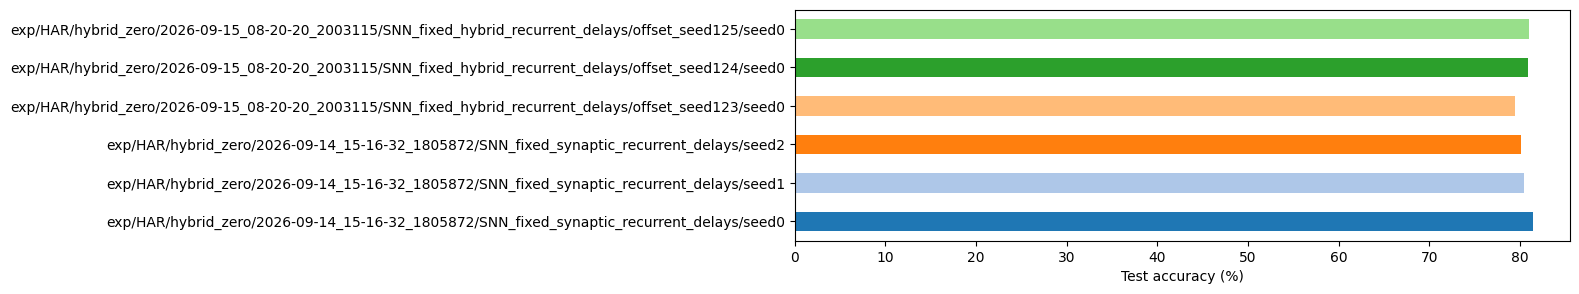

,exp/HAR/hybrid_zero/2026-09-14_15-16-32_1805872/SNN_fixed_synaptic_recurrent_delays/seed0,exp/HAR/hybrid_zero/2026-09-14_15-16-32_1805872/SNN_fixed_synaptic_recurrent_delays/seed1,exp/HAR/hybrid_zero/2026-09-14_15-16-32_1805872/SNN_fixed_synaptic_recurrent_delays/seed2,exp/HAR/hybrid_zero/2026-09-15_08-20-20_2003115/SNN_fixed_hybrid_recurrent_delays/offset_seed123/seed0,exp/HAR/hybrid_zero/2026-09-15_08-20-20_2003115/SNN_fixed_hybrid_recurrent_delays/offset_seed124/seed0,exp/HAR/hybrid_zero/2026-09-15_08-20-20_2003115/SNN_fixed_hybrid_recurrent_delays/offset_seed125/seed0
delay_std_init,3,3,3,0.0,0.0,0.0
hybrid_delay_seed,123,123,123,123,124,125
init_rec_delay,uniform_integer,uniform_integer,uniform_integer,half_normal,half_normal,half_normal
results_dir,exp/HAR/hybrid_zero/2026-09-14_15-16-32_180587...,exp/HAR/hybrid_zero/2026-09-14_15-16-32_180587...,exp/HAR/hybrid_zero/2026-09-14_15-16-32_180587...,exp/HAR/hybrid_zero/2026-09-15_08-20-20_200311...,exp/HAR/hybrid_zero/2026-09-15_08-20-20_200311...,exp/HAR/hybrid_zero/2026-09-15_08-20-20_200311...
seed,0,1,2,0,0,0


In [27]:
scores = pd.Series({k:r['final']['acc'] for k,r in runs.items() if 'acc' in r['final']}, name='Test accuracy (%)')
if len(scores):
    ax = scores.plot.barh(figsize=(10, max(3, len(scores)*0.4)), color=[colors[k] for k in scores.index])
    ax.set_xlabel(scores.name)
    plt.show()
else:
    print('Aucun score de test disponible.')
configs = pd.DataFrame({k:r['config'] for k,r in runs.items()}).astype(str)
display(configs.loc[configs.nunique(axis=1) > 1])


In [28]:
rows = []
for name, r in runs.items():
    rows.append({
        "model": r["final"].get("model", r["path"].parent.name),
        "std_initiale": r["config"].get("delay_std_init"),
        "accuracy": r["final"].get("acc"),
    })

df = pd.DataFrame(rows).dropna(subset=["accuracy"])

stats = (
    df.groupby(["model", "std_initiale"])["accuracy"]
    .agg(n="count", moyenne="mean", ecart_type="std")
    .reset_index()
)

display(stats.round(3))

,model,std_initiale,n,moyenne,ecart_type
0,SNN_fixed_hybrid_recurrent_delays,0.0,3,80.470,0.839
1,SNN_fixed_synaptic_recurrent_delays,3.0,3,80.669,0.668


In [29]:
from collections import defaultdict
import numpy as np
import pandas as pd

groupes = defaultdict(list)

for name, r in runs.items():
    path = r["path"] / "final_delays.npz"
    if not path.exists():
        continue

    cfg = r["config"]
    cle = (
        r["final"].get("model", r["path"].parent.name),
        cfg.get("init_rec_delay"),
        cfg.get("delay_std_init"),
        cfg.get("hybrid_max_synaptic_delay"),
    )

    with np.load(path) as archive:
        arrays = [archive[k].ravel() for k in archive.files]
        if arrays:
            d = np.concatenate(arrays)
            if d.size:
                groupes[cle].append(d)

rows = []
for (model, init, std, offset_max), arrays in groupes.items():
    d = np.concatenate(arrays)
    rows.append({
        "model": model,
        "initialisation": init,
        "std_initiale": std,
        "offset_max": offset_max,
        "n_runs": len(arrays),
        "n_delais": d.size,
        "moyenne": d.mean(),
        "ecart_type": d.std(),
        "min": d.min(),
        "mediane": np.median(d),
        "max": d.max(),
        "zeros_%": 100 * np.mean(d == 0),
    })

display(pd.DataFrame(rows).round(3))

,model,initialisation,std_initiale,offset_max,n_runs,n_delais,moyenne,ecart_type,min,mediane,max,zeros_%
0,SNN_fixed_synaptic_recurrent_delays,uniform_integer,3.0,4,3,142080,2.005,1.415,0.0,2.0,4.0,19.971
1,SNN_fixed_hybrid_recurrent_delays,half_normal,0.0,4,3,142080,2.003,1.415,0.0,2.0,4.0,20.018


In [30]:
stats_delais.groupby(["std_initiale"]).agg(moyenne=("moyenne", "mean"), ecart_type=("ecart_type", "mean"), min=("min", "min"), max=("max", "max")).round(3)

NameError: name 'stats_delais' is not defined

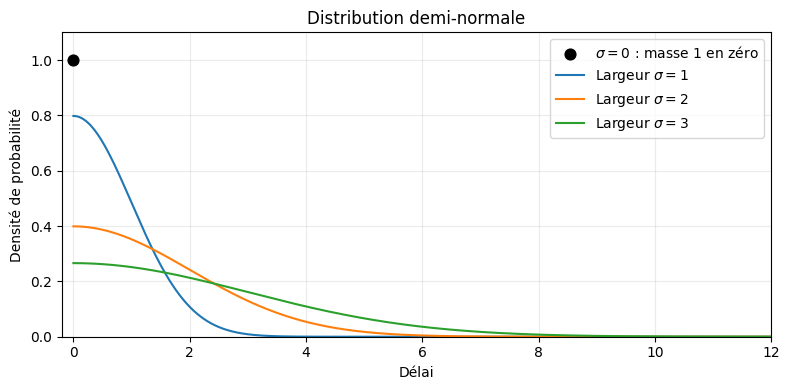

In [27]:
import numpy as np
import matplotlib.pyplot as plt

sigmas = [0, 1, 2, 3]
x = np.linspace(0, 12, 1000)

fig, ax = plt.subplots(figsize=(8, 4))

for sigma in sigmas:
    if sigma == 0:
        ax.scatter(0, 1, color="black", s=60, zorder=5,
                   label=r"$\sigma=0$ : masse 1 en zéro")
    else:
        densite = np.sqrt(2 / np.pi) / sigma * np.exp(-x**2 / (2 * sigma**2))
        ax.plot(x, densite, label=fr"Largeur $\sigma={sigma}$")

ax.set(
    xlabel="Délai",
    ylabel="Densité de probabilité",
    title="Distribution demi-normale",
    xlim=(-0.2, 12),
    ylim=(0, 1.1),
)
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Courbes accuracy / loss
Les CSV du dépôt stockent les métriques en lignes et les époques en colonnes. Les époques affichées commencent à 1.

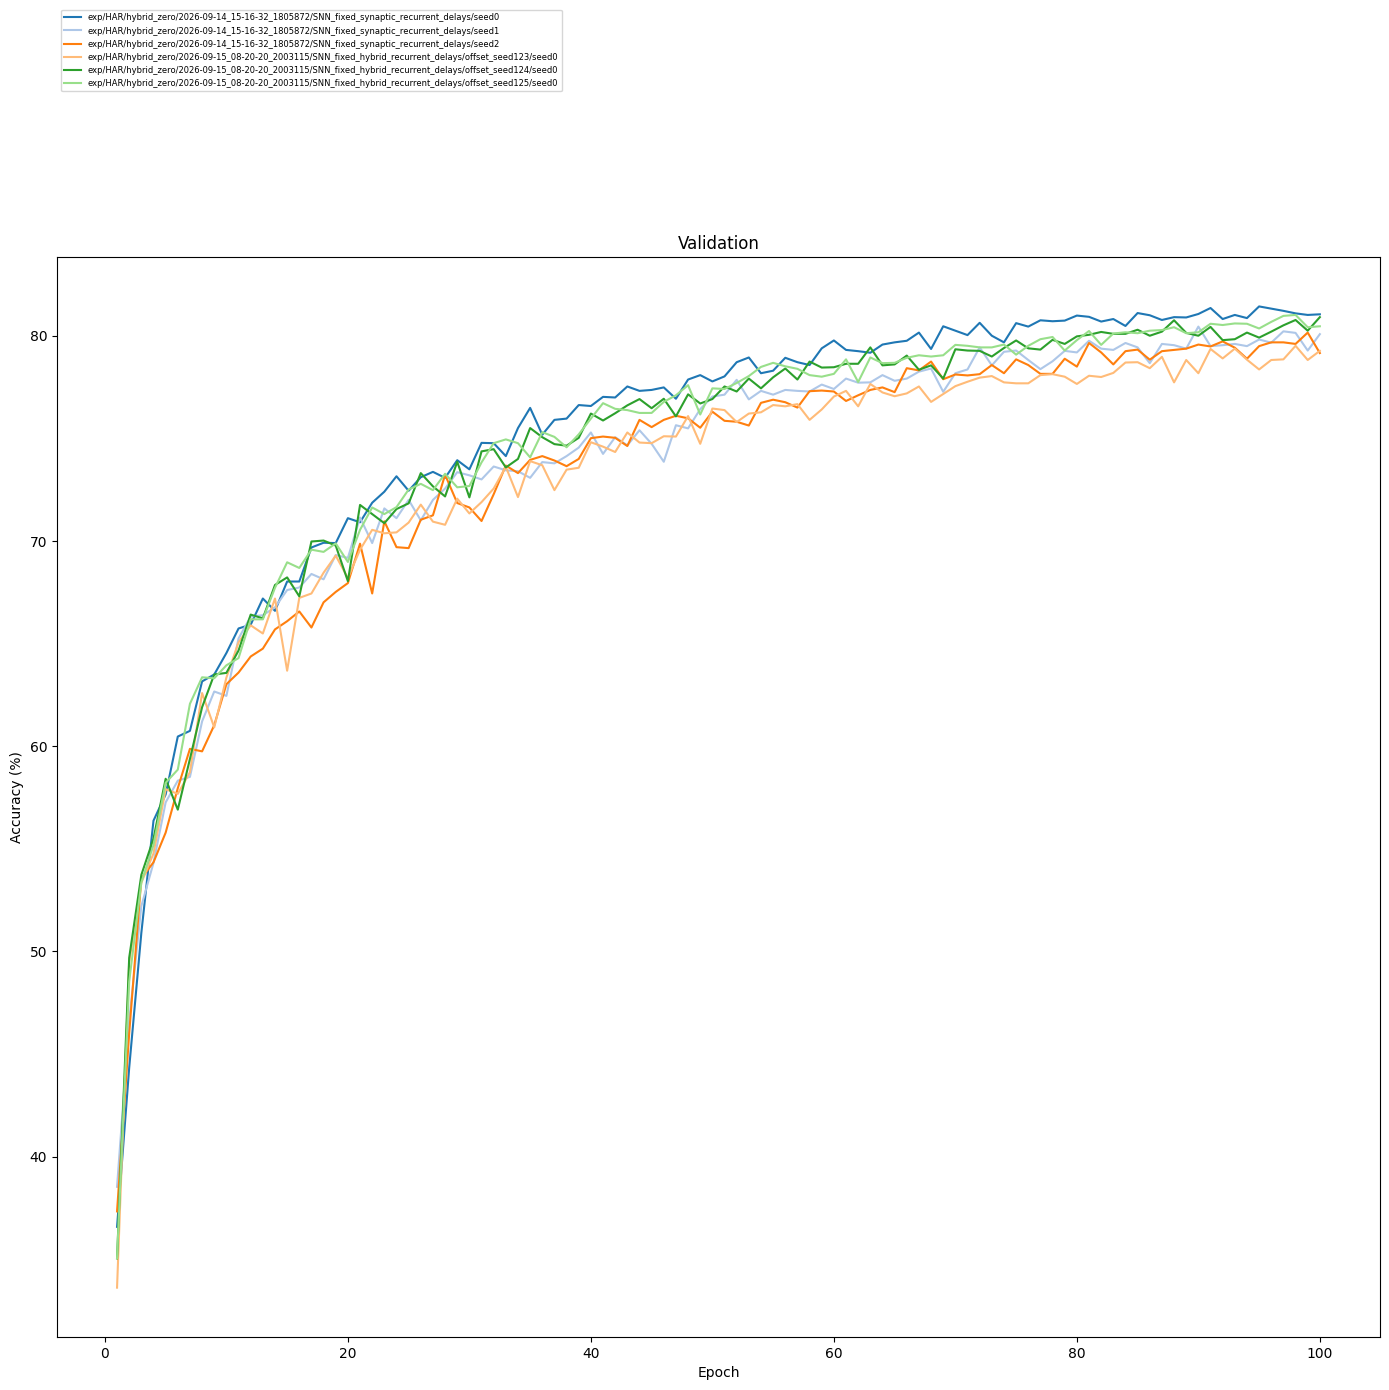

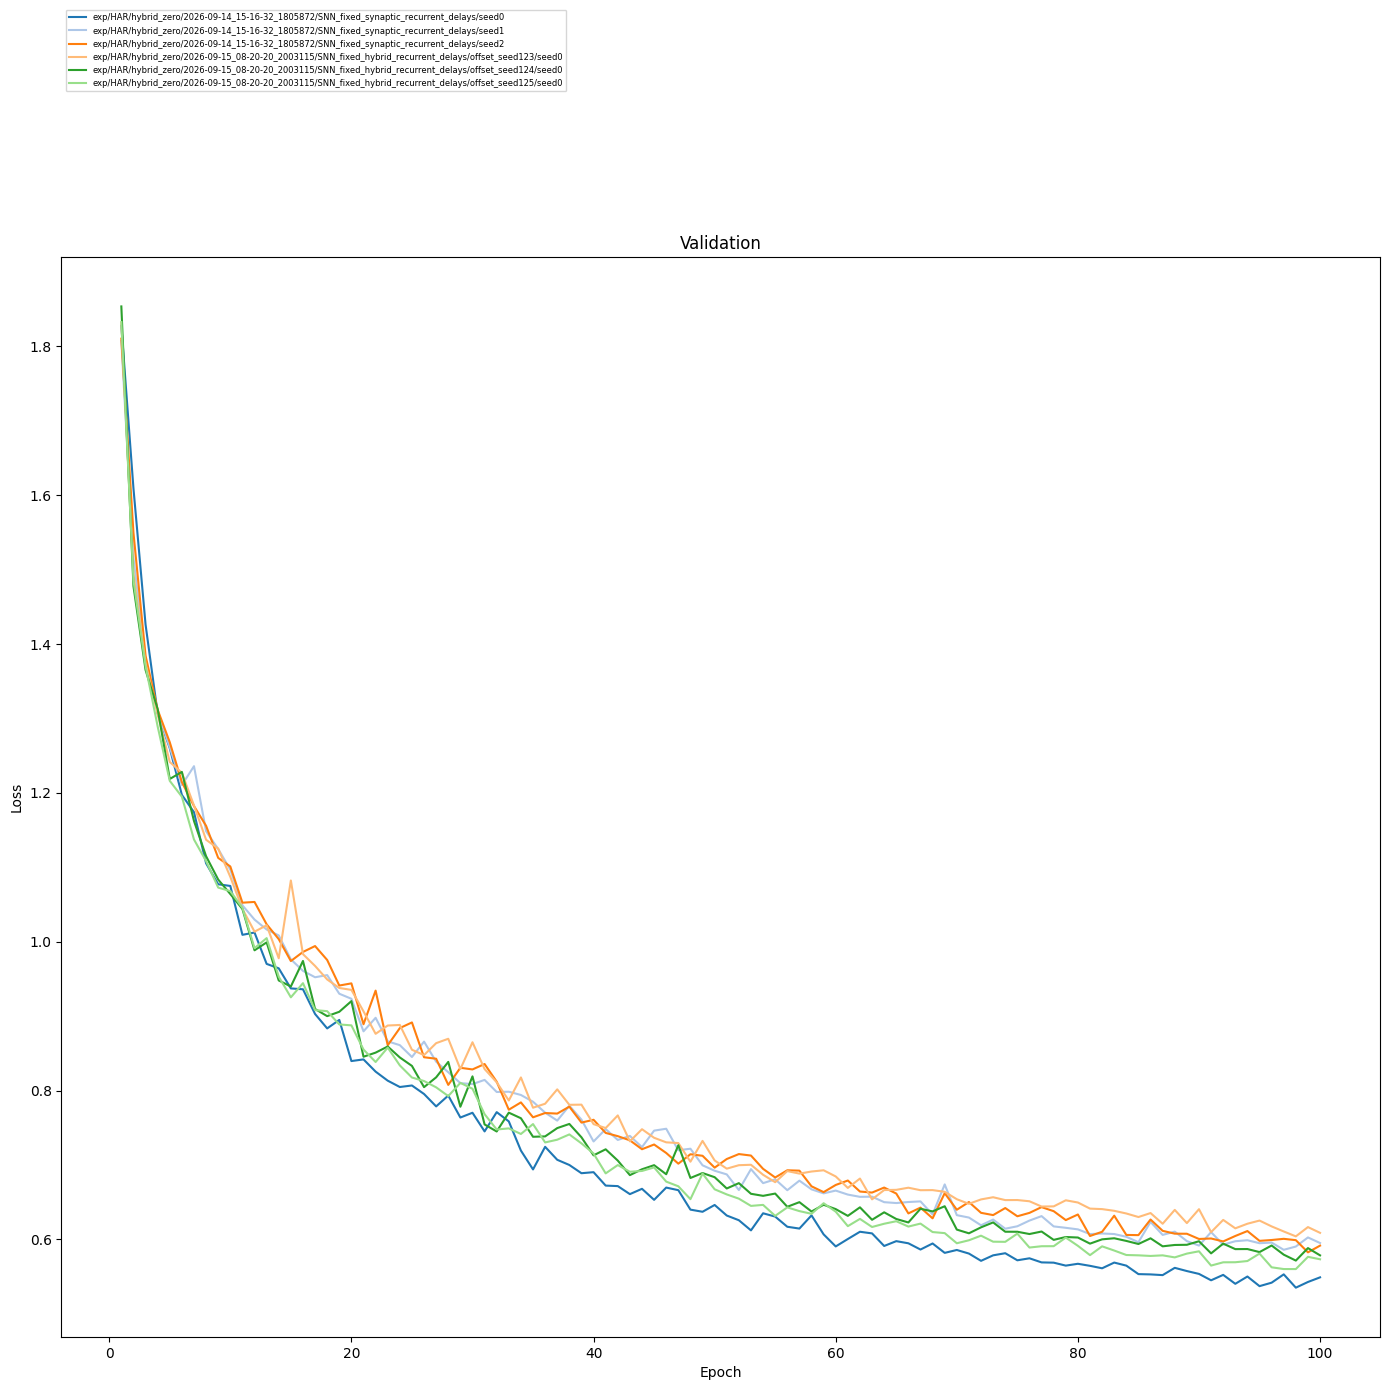

In [31]:
for row, metric in enumerate(['Accuracy (%)', 'Loss']):
    fig, ax = plt.subplots(figsize=(14, 14))

    for k, r in runs.items():
        path = r['path'] / 'val_res.csv'
        if not path.exists():
            continue

        frame = pd.read_csv(path, index_col=0)
        epochs = np.array(frame.columns, dtype=int) + 1

        ax.plot(
            epochs, frame.iloc[row].to_numpy(dtype=float),
            label=k, color=colors[k]
        )

    ax.set(title='Validation', ylabel=metric, xlabel='Epoch')
    ax.legend(fontsize=6, bbox_to_anchor=(0, 1.15), loc='lower left')
    fig.tight_layout()
    plt.show()

## Distributions finales par couche
Histogrammes normalisés : un axone est une observation pour le modèle axonal, une synapse pour les modèles synaptique et hybride. L’écart-type décrit la dispersion des délais, pas l’incertitude entre seeds.

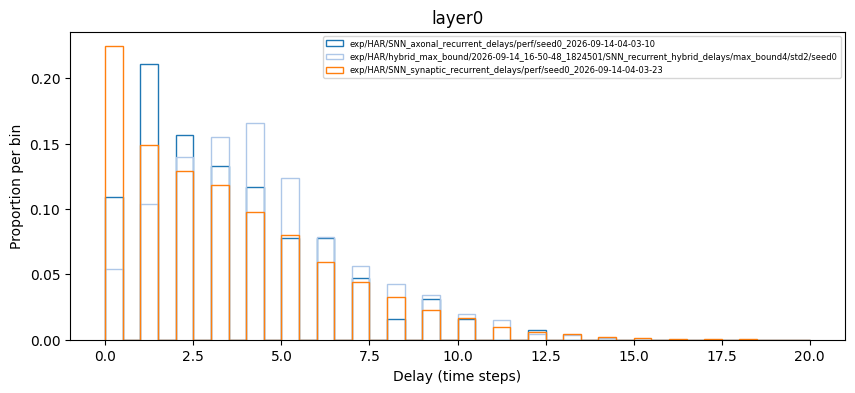

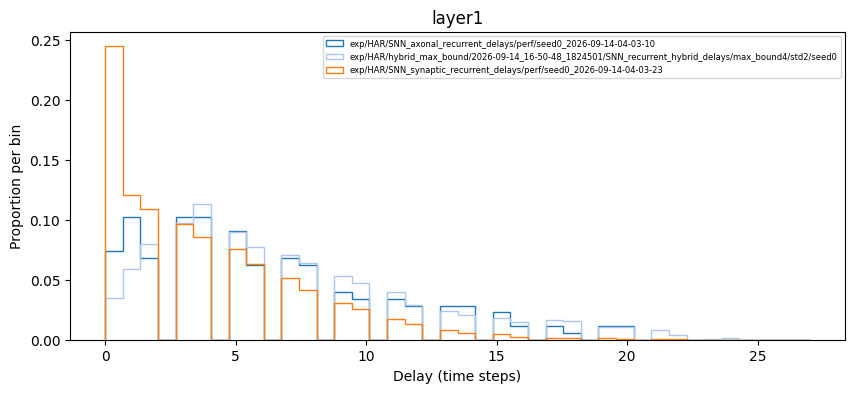

,run,layer,n,mean,std,median,minimum,maximum,zero_pct
0,exp/HAR/SNN_axonal_recurrent_delays/perf/seed0...,layer0,128,3.234375,2.593515,3.0,0.0,12.0,10.937500
1,exp/HAR/hybrid_max_bound/2026-09-14_16-50-48_1...,layer0,16384,4.145630,2.687733,4.0,0.0,14.0,5.389404
2,exp/HAR/SNN_synaptic_recurrent_delays/perf/see...,layer0,16384,3.170776,3.027262,2.0,0.0,20.0,22.436523
3,exp/HAR/SNN_axonal_recurrent_delays/perf/seed0...,layer1,176,6.204545,4.828088,5.0,0.0,20.0,7.386364
4,exp/HAR/hybrid_max_bound/2026-09-14_16-50-48_1...,layer1,30976,7.002389,4.995038,6.0,0.0,24.0,3.483342
5,exp/HAR/SNN_synaptic_recurrent_delays/perf/see...,layer1,30976,3.685950,3.675469,3.0,0.0,27.0,24.438275


In [15]:
def snapshot(path):
    if not path.exists(): return {}
    with np.load(path, allow_pickle=False) as z:
        return {k: z[k].astype(float).ravel() for k in z.files}
finals = {k:snapshot(r['path'] / 'final_delays.npz') for k,r in runs.items()}
layers = sorted({layer for z in finals.values() for layer in z})
rows = []
for layer in layers:
    fig,ax = plt.subplots(figsize=(10,4))
    values = [z[layer] for z in finals.values() if layer in z]
    bins = np.histogram_bin_edges(np.concatenate(values), bins=40)
    for k,z in finals.items():
        if layer not in z: continue
        a=z[layer]
        ax.hist(a, bins=bins, weights=np.ones(a.size)/a.size, histtype='step', label=k, color=colors[k])
        rows.append(dict(run=k, layer=layer, n=a.size, mean=a.mean(), std=a.std(),
                         median=np.median(a), minimum=a.min(), maximum=a.max(), zero_pct=100*np.mean(a==0)))
    ax.set(title=layer, xlabel='Delay (time steps)', ylabel='Proportion per bin')
    ax.legend(fontsize=6, bbox_to_anchor=(1,1))
    plt.show()
stats = pd.DataFrame(rows)
display(stats)


## Évolution des délais
Pour les anciens runs : comparaison **initialisation / meilleur modèle**, sans interpolation entre ces deux états.
Pour les prochains runs, ajouter `--save-delay-history` à la commande `experiments/train.py` : les snapshots sont enregistrés après chaque validation dans `delay_history/epoch_XXXX.npz` (indices à partir de zéro).
Les courbes représentent donc les délais après la projection éventuelle réalisée lors de la validation. Elles ne représentent pas les fluctuations à l'intérieur d'une époque.


exp/HAR/SNN_axonal_recurrent_delays/perf/seed0_2026-09-14-04-03-10 : aucun historique par époque disponible.


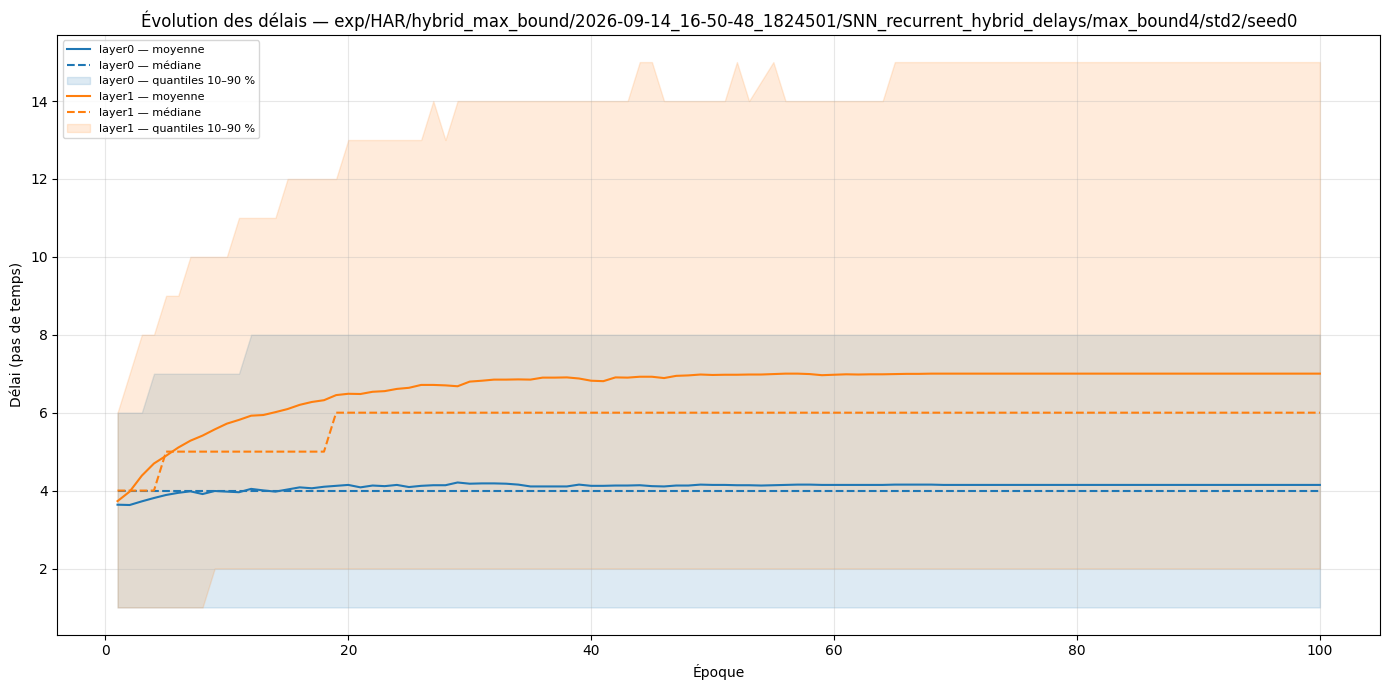

exp/HAR/SNN_synaptic_recurrent_delays/perf/seed0_2026-09-14-04-03-23 : aucun historique par époque disponible.


In [18]:
for k, r in runs.items():
    history = sorted(
        (r['path'] / 'delay_history').glob('epoch_*.npz'),
        key=lambda p: int(p.stem.split('_')[-1])
    )

    if not history:
        print(f"{k} : aucun historique par époque disponible.")
        continue

    records = []
    for path in history:
        epoch = int(path.stem.split('_')[-1]) + 1

        with np.load(path, allow_pickle=False) as data:
            for layer in data.files:
                delays = data[layer].astype(float).ravel()
                if delays.size == 0:
                    continue

                records.append({
                    'epoch': epoch,
                    'layer': layer,
                    'mean': delays.mean(),
                    'median': np.median(delays),
                    'q10': np.quantile(delays, 0.1),
                    'q90': np.quantile(delays, 0.9),
                })

    if not records:
        continue

    trajectory = pd.DataFrame(records)
    fig, ax = plt.subplots(figsize=(14, 7))

    for layer, group in trajectory.groupby('layer'):
        group = group.sort_values('epoch')
        line, = ax.plot(
            group['epoch'], group['mean'],
            label=f'{layer} — moyenne'
        )
        ax.plot(
            group['epoch'], group['median'],
            linestyle='--', color=line.get_color(),
            label=f'{layer} — médiane'
        )
        ax.fill_between(
            group['epoch'], group['q10'], group['q90'],
            color=line.get_color(), alpha=0.15,
            label=f'{layer} — quantiles 10–90 %'
        )

    ax.set(
        title=f'Évolution des délais — {k}',
        xlabel='Époque',
        ylabel='Délai (pas de temps)'
    )
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()


exp/HAR/SNN_axonal_recurrent_delays/perf/seed0_2026-09-14-04-03-10 : aucun historique par époque disponible.


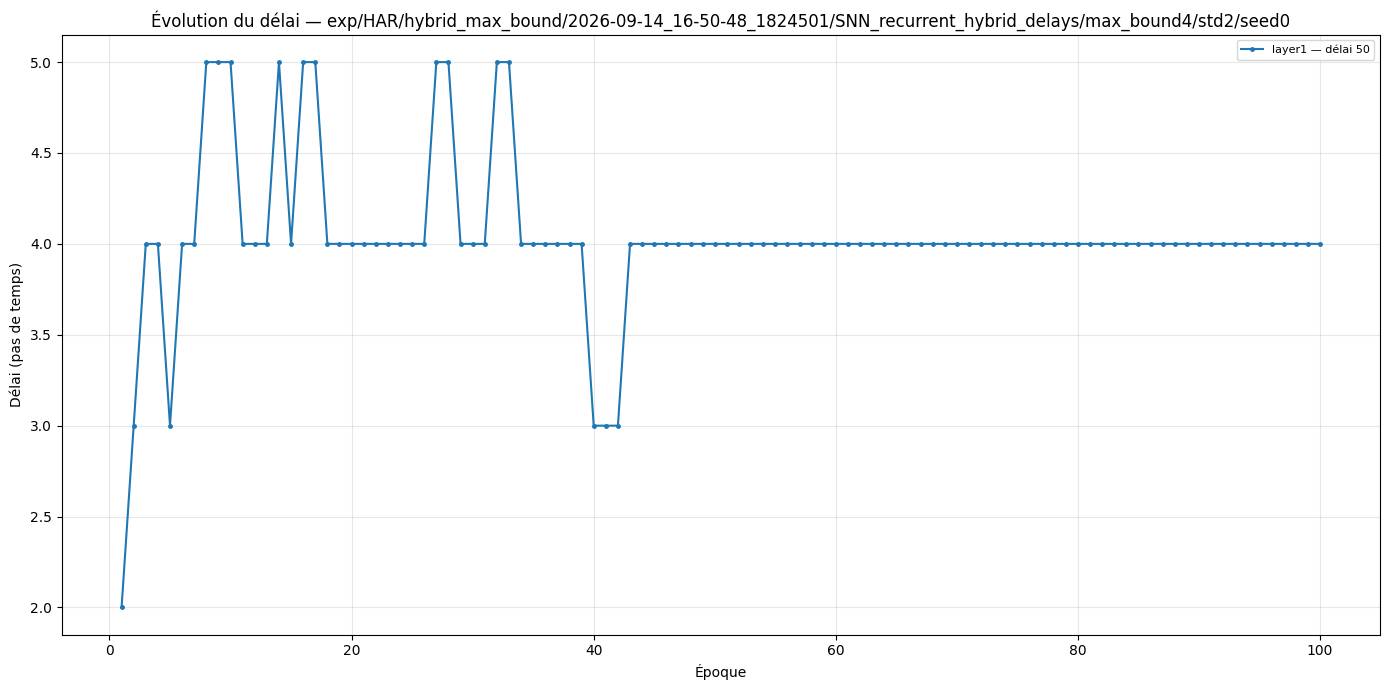

exp/HAR/SNN_synaptic_recurrent_delays/perf/seed0_2026-09-14-04-03-23 : aucun historique par époque disponible.


In [23]:
selected_layer = "layer1"   # Puis remplace par le nom de la couche
delay_index = 50   # Indice du délai à suivre (à partir de 0)

for k, r in runs.items():
    history = sorted(
        (r['path'] / 'delay_history').glob('epoch_*.npz'),
        key=lambda p: int(p.stem.split('_')[-1])
    )

    if not history:
        print(f"{k} : aucun historique par époque disponible.")
        continue

    if selected_layer is None:
        with np.load(history[0], allow_pickle=False) as data:
            print(f"\n{k} — couches disponibles :")
            for layer in data.files:
                print(f"  {layer} : {data[layer].size} délais")
        continue

    records = []
    for path in history:
        epoch = int(path.stem.split('_')[-1]) + 1

        with np.load(path, allow_pickle=False) as data:
            if selected_layer not in data.files:
                continue

            delays = data[selected_layer].astype(float).ravel()
            if not 0 <= delay_index < delays.size:
                raise IndexError(
                    f"{k}, {selected_layer} : indice {delay_index} invalide "
                    f"(nombre de délais : {delays.size})"
                )

            records.append({
                'epoch': epoch,
                'delay': delays[delay_index],
            })

    if not records:
        print(f"{k} : couche {selected_layer!r} absente de l'historique.")
        continue

    trajectory = pd.DataFrame(records).sort_values('epoch')
    fig, ax = plt.subplots(figsize=(14, 7))

    ax.plot(
        trajectory['epoch'], trajectory['delay'],
        marker='.', markersize=5,
        label=f'{selected_layer} — délai {delay_index}'
    )

    ax.set(
        title=f'Évolution du délai — {k}',
        xlabel='Époque',
        ylabel='Délai (pas de temps)'
    )
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()